
# SAHTE BANKNOT TESPİTİ
## 6. Hafta — Veri Analizi ve Google Colab Çalışması



### Proje Ekibi
- **Miraç Yaşar**
- **Buğra Ahat**
- **İbrahim Alo**

---

> **Çalışmanın amacı:** UCI Banknote Authentication veri setinin tamamını incelemek, temel betimsel istatistikleri hesaplamak ve elde edilen sonuçları grafiklerle görselleştirmek.


## A. Veri Tanıtımı

### 1. Veri Setinin Genel Bilgileri

| Özellik | Açıklama |
|---|---|
| **Adı** | Banknote Authentication |
| **Kaynak** | UCI Machine Learning Repository |
| **Hazırlayan** | Volker Lohweg (2012) |
| **Kayıt sayısı** | 1.372 |
| **Sütun sayısı** | 5 |
| **Lisans** | Creative Commons Attribution 4.0 (CC BY 4.0) |
| **Dosya biçimi** | Virgülle ayrılmış TXT, ZIP içerisinde |

**Resmî veri seti bağlantısı:**  
https://archive.ics.uci.edu/dataset/267/banknote

**DOI:** https://doi.org/10.24432/C55P57

**Erişim tarihi:** 04.11.2026

### 2. Veri Setinin Sütunları

| Sütun | Açıklama | Veri Türü |
|---|---|---|
| `variance` | Dalgacık dönüşümlü görüntünün varyansı | Continuous |
| `skewness` | Dalgacık dönüşümlü görüntünün çarpıklığı | Continuous |
| `curtosis` | Dalgacık dönüşümlü görüntünün basıklığı | Continuous |
| `entropy` | Görüntünün entropisi | Continuous |
| `class` | Banknot sınıfını belirten etiket | Integer |

### 3. Verinin Niteliği

- Veri seti **gerçek araştırma verilerine** dayanmaktadır.
- Dört sayısal özellik ve bir sınıf etiketi içerir.
- Ham banknot fotoğrafları yerine görüntülerden önceden çıkarılmış sayısal özellikler bulunmaktadır.
- Özelliklerin fiziksel ölçü birimi kaynakta belirtilmemiştir.
- Veri setinde **eksik değer bulunmamaktadır**.
- Çalışmada veri setindeki **1.372 kaydın tamamı** incelenmiştir.

### 4. Ekip Üyeleri ve Görev Dağılımı

| Ekip Üyesi | Görev ve Sorumluluk |
|---|---|
| **İbrahim Alo** | Google Colab uygulaması, istatistiksel hesaplamalar ve grafiklerin hazırlanması |
| **Miraç Yaşar** | GitHub depo yönetimi, dosya organizasyonu ve proje tesliminin koordinasyonu |
| **Buğra Ahat** | Veri kaynağının, lisans bilgilerinin, analiz sonuçlarının bağımsız kontrolü ve akademik yorumun hazırlanması |


## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki örneği çalıştırın. Ardından **kendi dosyanızı** `veri_yolu` değişkeniyle gösterebilirsiniz.

In [2]:

import pandas as pd

from google.colab import files

# Veri setini bilgisayardan yukle
yuklenen = files.upload()
dosya_adi = next(iter(yuklenen))

satir_basliklari = ["variance", "skewness", "curtosis", "entropy", "class"]

veri = pd.read_csv(
    dosya_adi,
    header=None,
    names=satir_basliklari
)
print("Veri setinin boyutu:", veri.shape)
print(veri.head())

assert veri.shape == (1372, 5)


Veri setinin boyutu: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0


## C. Veri inceleme ve hesaplama
Kendi veri setinizi kullanırken sayısal sütun adlarını değiştirin. Sütun başlığında boşluk ve yazım farklarını kontrol edin.

In [3]:
ozellikler = ["variance", "skewness", "curtosis", "entropy"]

print("Boyut (satır, sütun):", veri.shape)
print("\nEksik değer sayıları:\n", veri.isna().sum())

istatistikler = veri[ozellikler].agg(["sum", "mean", "min", "max"]).round(4)
print("\nTüm 1372 kaydın istatistikleri:\n", istatistikler)

sinif_sayilari = veri["class"].value_counts().sort_index()
print("\nSınıf dağılımı:\n", sinif_sayilari)

print("\nKayıt sayısı:", len(veri))

Boyut (satır, sütun): (1372, 5)

Eksik değer sayıları:
 variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Tüm 1372 kaydın istatistikleri:
       variance   skewness   curtosis    entropy
sum   595.0848  2637.4685  1917.5444 -1634.9527
mean    0.4337     1.9224     1.3976    -1.1917
min    -7.0421   -13.7731    -5.2861    -8.5482
max     6.8248    12.9516    17.9274     2.4495

Sınıf dağılımı:
 class
0    762
1    610
Name: count, dtype: int64

Kayıt sayısı: 1372


## D. Grafik ve sonuç dosyaları
Grafiğin başlığını, eksenini ve ölçü birimini kendi verinize göre güncelleyin.

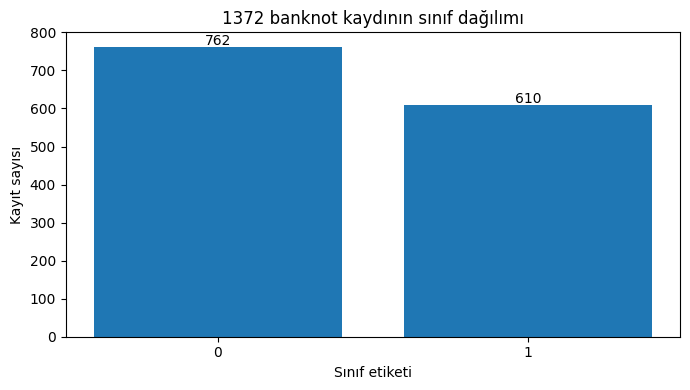

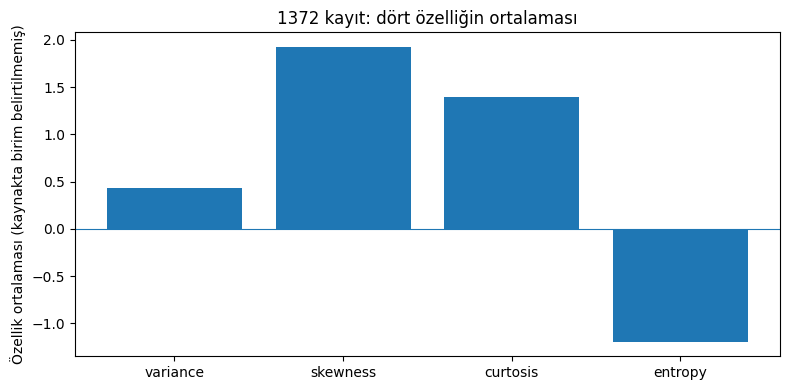

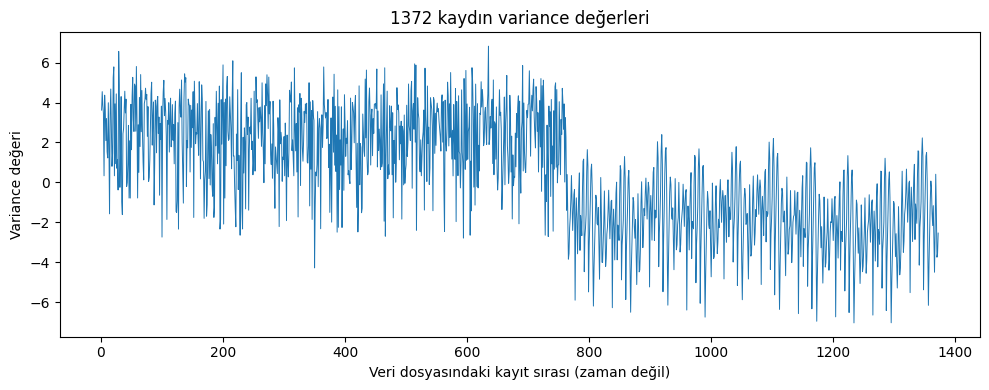

Kaydedilen dosyalar:
- outputs/istatistik_ozeti.csv
- outputs/ozellik_ortalamalari_sutun.png
- outputs/sinif_dagilimi_sutun.png
- outputs/sinif_sayilari.csv
- outputs/variance_tum_kayitlar_cizgi.png


In [4]:
from pathlib import Path
import matplotlib.pyplot as plt

klasor = Path("outputs")
klasor.mkdir(exist_ok=True)

# Grafik 1: Her iki sınıfın kayıt sayıları
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([str(x) for x in sinif_sayilari.index], sinif_sayilari.values)
ax.set_xlabel("Sınıf etiketi")
ax.set_ylabel("Kayıt sayısı")
ax.set_title("1372 banknot kaydının sınıf dağılımı")
for i, sayi in enumerate(sinif_sayilari.values):
    ax.text(i, sayi + 5, str(sayi), ha="center")
fig.tight_layout()
fig.savefig(klasor / "sinif_dagilimi_sutun.png", dpi=160)
plt.show()

# Grafik 2: Dört sayısal özelliğin tüm veri setindeki ortalamaları
fig, ax = plt.subplots(figsize=(8, 4))
ortalamalar = veri[ozellikler].mean()
ax.bar(ortalamalar.index, ortalamalar.values)
ax.axhline(0, linewidth=0.8)
ax.set_ylabel("Özellik ortalaması (kaynakta birim belirtilmemiş)")
ax.set_title("1372 kayıt: dört özelliğin ortalaması")
fig.tight_layout()
fig.savefig(klasor / "ozellik_ortalamalari_sutun.png", dpi=160)
plt.show()

# Grafik 3: Tüm kayıtların variance değeri, sırayla (zaman serisi DEĞİL)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(veri) + 1), veri["variance"], linewidth=0.7)
ax.set_xlabel("Veri dosyasındaki kayıt sırası (zaman değil)")
ax.set_ylabel("Variance değeri")
ax.set_title("1372 kaydın variance değerleri")
fig.tight_layout()
fig.savefig(klasor / "variance_tum_kayitlar_cizgi.png", dpi=160)
plt.show()

istatistikler.to_csv(klasor / "istatistik_ozeti.csv", encoding="utf-8-sig")
sinif_sayilari.rename("kayit_sayisi").to_csv(klasor / "sinif_sayilari.csv", encoding="utf-8-sig")
print("Kaydedilen dosyalar:")
for f in sorted(klasor.iterdir()):
    print("-", f)


## E. Akademik Yorum ve Genel Değerlendirme

### 1. Veri Kaynağı ve Analiz Kapsamı

Bu çalışmada **UCI Banknote Authentication** veri setindeki **1.372 kaydın tamamı**, dört sayısal özellik (`variance`, `skewness`, `curtosis`, `entropy`) ve bir sınıf etiketi (`class`) üzerinden incelenmiştir.

### 2. İstatistiksel Bulgular

Dört sayısal özelliğin ortalamaları sırasıyla **0,4337**, **1,9224**, **1,3976** ve **-1,1917** olarak hesaplanmış; toplam, minimum ve maksimum değerler de belirlenmiştir.

### 3. Grafiklerin Değerlendirilmesi

Sınıf dağılımı grafiğinde **0 etiketli 762 kayıt** ve **1 etiketli 610 kayıt** gösterilmiş, diğer sütun grafiğinde ise dört sayısal özelliğin ortalamaları karşılaştırılmıştır.

### 4. Analizin Sınırlılıkları

Çizgi grafiği bütün kayıtların `variance` değerlerini kayıt sırasına göre göstermekte olup bu sıra zaman sırası olmadığından sonuçlar zamansal bir eğilim olarak yorumlanmamıştır.

### 5. Genel Sonuç

Veri setinde **eksik değer bulunmamış** ve temel veri incelemesi tamamlanmış olmakla birlikte, bu çalışma herhangi bir makine öğrenmesi modelinin sınıflandırma başarısını ölçmemektedir.




## F. Teslim Kontrol Listesi

### Veri ve Analiz
- [x] Gerçek ve erişilebilir veri seti kullanıldı.
- [x] Veri kaynağı ve lisans bilgileri belirtildi.
- [x] 1.372 kaydın tamamı incelendi.
- [x] Toplam, ortalama, minimum ve maksimum hesaplandı.
- [x] Veri setindeki eksik değerler kontrol edildi.

### Grafik ve Raporlama
- [x] Sütun grafikleri oluşturuldu.
- [x] Çizgi grafiği oluşturuldu.
- [x] Grafikler için açıklamalar hazırlandı.
- [x] Beş cümlelik akademik yorum yazıldı.

### GitHub ve Teslim
- [x] Notebook dosyası `.ipynb` biçiminde kaydedildi.
- [x] Grafik dosyaları indirildi.
- [x] Dosyalar GitHub deposuna yüklendi.
- [x] README içerisinde ekip katkıları kontrol edildi.
- [x] Son teslim düzeni ekip tarafından doğrulandı.

---

**GitHub deposu:**  
https://github.com/miracayasar/Sahte-Banknot-Tespiti


